In [25]:
!pip install -q kagglehub

In [26]:
import kagglehub

path = kagglehub.dataset_download("juanthomaswijaya/indonesian-license-plate-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'indonesian-license-plate-dataset' dataset.
Path to dataset files: /kaggle/input/indonesian-license-plate-dataset


In [27]:
!ls -la "/root/.cache/kagglehub/datasets/juanthomaswijaya/indonesian-license-plate-dataset/versions/1"

total 16
drwxr-xr-x 4 root root 4096 Nov 14 09:13  .
drwxr-xr-x 3 root root 4096 Nov 14 09:13  ..
drwxr-xr-x 5 root root 4096 Nov 14 09:13 'Indonesian License Plate Dataset'
drwxr-xr-x 4 root root 4096 Nov 14 09:13 'Indonesian License Plate Recognition Dataset'


Train004_2.jpt

In [56]:
import os
import re
import glob
import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import easyocr

from sklearn.metrics import precision_recall_fscore_support, confusion_matrix
# Path dataset hasil download kagglehub
dataset_root = "/root/.cache/kagglehub/datasets/juanthomaswijaya/indonesian-license-plate-dataset/versions/1/Indonesian License Plate Recognition Dataset"
assert os.path.exists(dataset_root), "Folder dataset tidak ditemukan! Pastikan kagglehub sudah dijalankan."
# Muat daftar kelas karakter (0-9, A-Z)
with open(os.path.join(dataset_root, "classes.names"), "r") as f:
    CLASS_NAMES = [line.strip() for line in f if line.strip()]
# Inisialisasi EasyOCR (1x saja)
reader = easyocr.Reader(['en'], gpu=True)
print("✅ Setup selesai & EasyOCR siap!")

✅ Setup selesai & EasyOCR siap!


In [73]:
# ==============================================================================
# 1. PREPROCESSING (P4 Grayscale, Deskewing, P7 Bilateral, P6 Smart CLAHE)
# ==============================================================================
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

def deskew_plate(gray_img, max_angle=15.0):
    edges = cv2.Canny(gray_img, 50, 150)
    lines = cv2.HoughLinesP(edges, 1, np.pi / 180, threshold=30,
                            minLineLength=gray_img.shape[1] // 3, maxLineGap=10)
    if lines is None:
        return gray_img, 0.0
    angles = [np.degrees(np.arctan2(l[0][3] - l[0][1], l[0][2] - l[0][0])) for l in lines]
    angles = [a for a in angles if abs(a) <= max_angle]
    if not angles:
        return gray_img, 0.0
    median_angle = float(np.median(angles))
    h, w = gray_img.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), median_angle, 1.0)
    return cv2.warpAffine(gray_img, M, (w, h), flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REPLICATE), round(median_angle, 2)

def preprocess_plate(bgr_img):
    gray = cv2.cvtColor(bgr_img, cv2.COLOR_BGR2GRAY)
    deskewed, angle = deskew_plate(gray)
    # Lewati smoothing jika gambar sangat kecil agar tidak makin kabur
    smoothed = cv2.bilateralFilter(deskewed, d=5, sigmaColor=35, sigmaSpace=35) if gray.shape[0] >= 50 else deskewed
    mean_v, std_v = float(np.mean(smoothed)), float(np.std(smoothed))
    enhanced = clahe.apply(smoothed) if (std_v < 45.0 or mean_v < 45.0) else smoothed.copy()
    return gray, deskewed, smoothed, enhanced

# ==============================================================================
# 2. SEGMENTASI DUAL-ROI (P8 Unsharp, P12 Binarisasi, P13-14 Morfologi)
# ==============================================================================
def normalize_polarity(binary_img):
    white_ratio = np.sum(binary_img == 255) / float(binary_img.size)
    return cv2.bitwise_not(binary_img) if white_ratio < 0.5 else binary_img.copy()

def process_main_plate_roi(enhanced_gray):
    h, w = enhanced_gray.shape[:2]
    roi = enhanced_gray[int(h*0.04):int(h*0.74), int(w*0.03):int(w*0.97)]
    scale = 140.0 / roi.shape[0] if roi.shape[0] < 140 else 1.0
    up = cv2.resize(roi, (int(roi.shape[1]*scale), int(roi.shape[0]*scale)), interpolation=cv2.INTER_CUBIC)
    blur = cv2.GaussianBlur(up, (0, 0), 2.0)
    sharp = cv2.addWeighted(up, 1.6, blur, -0.6, 0)

    _, otsu = cv2.threshold(sharp, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    # block_size diperbesar ke 51 agar huruf tebal tidak berlubang/terputus
    adap = cv2.adaptiveThreshold(sharp, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 51, 10)

    def clean(bin_img):
        norm = normalize_polarity(bin_img)
        ch_mask = cv2.bitwise_not(norm)
        n, labels, stats, _ = cv2.connectedComponentsWithStats(ch_mask, connectivity=8)
        cleaned = norm.copy()
        nh, nw = norm.shape[:2]
        if n > 1:
            min_a = max(20, int(norm.size * 0.0015))
            cands = [stats[i][3] for i in range(1, n) if stats[i][4] >= min_a and stats[i][2] <= 0.45*nw]
            max_h = max(cands) if cands else nh
            for i in range(1, n):
                x, y, cw, ch, area = stats[i]
                # Hanya buang komponen yang jelas bingkai lebar, bintik kecil, atau sangat pendek
                if cw > 0.45*nw or area < min_a or ch < 0.40*max_h:
                    cleaned[labels == i] = 255
        return cv2.copyMakeBorder(cleaned, 15, 15, 20, 20, cv2.BORDER_CONSTANT, value=255)

    sharp_pad = cv2.copyMakeBorder(sharp, 15, 15, 20, 20, cv2.BORDER_REPLICATE)
    return clean(otsu), clean(adap), sharp_pad

    # Pengaman: jika hampir semua piksel hitam terhapus,, kembalikan norm tanpa filter
    if np.sum(cleaned == 0) < 100:
      cleaned = norm
    return cv2.copyMakeBorder(cleaned, 15, 15, 20, 20, cv2.BORDER_CONSTANT, value=255)

def process_tax_roi(enhanced_gray):
    h, w = enhanced_gray.shape[:2]
    tax_crop = enhanced_gray[int(h*0.66):int(h*0.91), int(w*0.28):int(w*0.72)]
    scale = 120.0 / max(1, tax_crop.shape[0])
    tax_up = cv2.resize(tax_crop, (int(tax_crop.shape[1]*scale), 120), interpolation=cv2.INTER_CUBIC)
    blur = cv2.GaussianBlur(tax_up, (0, 0), 2.0)
    tax_sharp = cv2.addWeighted(tax_up, 1.8, blur, -0.8, 0)

    _, tax_otsu = cv2.threshold(tax_sharp, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    tax_adap = cv2.adaptiveThreshold(tax_sharp, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 25, 6)

    def clean_tax(bin_img):
        norm = normalize_polarity(bin_img)
        ch_mask = cv2.bitwise_not(norm)
        n, labels, stats, _ = cv2.connectedComponentsWithStats(ch_mask, connectivity=8)
        cleaned = norm.copy()
        nw = norm.shape[1]
        for i in range(1, n):
            if stats[i][2] > 0.45 * nw or stats[i][4] < 15:
                cleaned[labels == i] = 255
        return cv2.copyMakeBorder(cleaned, 15, 15, 20, 20, cv2.BORDER_CONSTANT, value=255)

    tax_sharp_pad = cv2.copyMakeBorder(tax_sharp, 15, 15, 20, 20, cv2.BORDER_REPLICATE)
    return clean_tax(tax_otsu), clean_tax(tax_adap), tax_sharp_pad

# ==============================================================================
# 3. OCR & CONTEXT-AWARE REGEX
# ==============================================================================
DICT_CHAR_TO_INT = {'O': '0', 'D': '0', 'Q': '0', 'I': '1', 'L': '1', 'T': '1', 'Z': '2', 'A': '4', 'S': '5', 'G': '6', 'B': '8'}
DICT_INT_TO_CHAR = {'0': 'O', '1': 'I', '2': 'Z', '4': 'A', '5': 'S', '6': 'G', '7': 'T', '8': 'B'}

def fix_plate_by_position(raw):
    m_strict = re.fullmatch(r'([A-Z]{1,2})([0-9]{1,4})([A-Z]{1,3})', raw)
    if m_strict:
        return f"{m_strict.group(1)} {m_strict.group(2)} {m_strict.group(3)}", True
    if 4 <= len(raw) <= 9:
        for f_len in (1, 2):
            for b_len in (2, 3, 1):
                m_len = len(raw) - f_len - b_len
                if 1 <= m_len <= 4:
                    cand = ("".join(DICT_INT_TO_CHAR.get(c, c) for c in raw[:f_len]) +
                            "".join(DICT_CHAR_TO_INT.get(c, c) for c in raw[f_len:f_len+m_len]) +
                            "".join(DICT_INT_TO_CHAR.get(c, c) for c in raw[f_len+m_len:]))
                    m2 = re.fullmatch(r'([A-Z]{1,2})([0-9]{1,4})([A-Z]{1,3})', cand)
                    if m2:
                        return f"{m2.group(1)} {m2.group(2)} {m2.group(3)}", True
    return raw, False

def recognize_main_plate(images_dict, min_conf=0.60):
    candidates = []
    for source_name, img in images_dict.items():
        res = reader.readtext(img, allowlist='0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZ',
                              paragraph=False, min_size=5, text_threshold=0.4, low_text=0.3, width_ths=1.5)
        if not res:
            continue
        res.sort(key=lambda x: min(p[0] for p in x[0]))
        raw = "".join(re.sub(r'[^A-Z0-9]', '', r[1].upper()) for r in res)
        conf = float(np.mean([r[2] for r in res]))
        fmt, regex_ok = fix_plate_by_position(raw)
        # Valid hanya jika Regex cocok DAN confidence >= min_conf
        is_valid = regex_ok and (conf >= min_conf)
        candidates.append({"source": source_name, "raw": raw, "fmt": fmt, "conf": conf, "valid": is_valid})

    if not candidates:
        return "TIDAK TERBACA", 0.0, False
    valid_cands = [c for c in candidates if c["valid"]]
    if valid_cands:
        scores = {}
        for c in valid_cands:
            scores.setdefault(c["fmt"], {"score": 0.0, "best": c})
            scores[c["fmt"]]["score"] += 1.0 + c["conf"]
            if c["conf"] > scores[c["fmt"]]["best"]["conf"]:
                scores[c["fmt"]]["best"] = c
        best = max(scores.values(), key=lambda s: s["score"])["best"]
    else:
        best = max(candidates, key=lambda c: (len(c["raw"]), c["conf"]))
    return best["fmt"], round(best["conf"], 2), best["valid"]

def recognize_tax_date(images_dict, min_conf=0.50):
    candidates = []
    for source_name, img in images_dict.items():
        res = reader.readtext(img, allowlist='0123456789',
                              paragraph=False, min_size=4, text_threshold=0.35, low_text=0.25, width_ths=1.5)
        if not res:
            continue
        res.sort(key=lambda x: min(p[0] for p in x[0]))
        digits = "".join(re.sub(r'[^0-9]', '', r[1]) for r in res)
        conf = float(np.mean([r[2] for r in res]))
        m = re.search(r'(0[1-9]|1[0-2])([0-9]{2})', digits)
        # Tolak tebakan ngawur jika confidence di bawah batas minimal
        if m and conf >= min_conf:
            candidates.append({"fmt": f"{m.group(1)}-{m.group(2)}", "conf": conf})
    if not candidates:
        return "-", 0.0, False
    best = max(candidates, key=lambda c: c["conf"])
    return best["fmt"], round(best["conf"], 2), True

# ==============================================================================
# 4. GROUND TRUTH, FILTER BLUR, & METRIK SLIDE 7
# ==============================================================================
def load_gt_from_txt(img_file):
    lbl_file = img_file.replace("/images/", "/labels/").replace(".jpg", ".txt")
    if not os.path.exists(lbl_file):
        return ""
    boxes = []
    with open(lbl_file, "r") as f:
        for line in f:
            p = line.strip().split()
            if len(p) >= 5:
                boxes.append((float(p[1]), CLASS_NAMES[int(p[0])]))
    boxes.sort(key=lambda x: x[0])
    raw = "".join(ch for _, ch in boxes)
    m = re.fullmatch(r'([A-Z]{1,2})([0-9]{1,4})([A-Z]{1,3})', raw)
    return f"{m.group(1)} {m.group(2)} {m.group(3)}" if m else raw

def is_too_blurry(gray_img, threshold=40.0):
    sharpness = cv2.Laplacian(gray_img, cv2.CV_64F).var()
    return sharpness < threshold, round(sharpness, 1)

def levenshtein_distance(s1, s2):
    if len(s1) < len(s2): return levenshtein_distance(s2, s1)
    if len(s2) == 0: return len(s1)
    prev_row = range(len(s2) + 1)
    for i, c1 in enumerate(s1):
        curr_row = [i + 1]
        for j, c2 in enumerate(s2):
            curr_row.append(min(prev_row[j + 1] + 1, curr_row[j] + 1, prev_row[j] + (c1 != c2)))
        prev_row = curr_row
    return prev_row[-1]

def evaluate_ocr_metrics(predictions, ground_truths):
    exact_matches, total_c_edits, total_c, total_w_edits, total_w = 0, 0, 0, 0, 0
    for pred, gt in zip(predictions, ground_truths):
        p_c, g_c = re.sub(r'[^A-Z0-9]', '', pred.upper()), re.sub(r'[^A-Z0-9]', '', gt.upper())
        if p_c == g_c: exact_matches += 1
        total_c_edits += levenshtein_distance(p_c, g_c)
        total_c += max(1, len(g_c))
        total_w_edits += levenshtein_distance(pred.upper().split(), gt.upper().split())
        total_w += max(1, len(gt.upper().split()))
    n = max(1, len(ground_truths))
    cer = (total_c_edits / total_c) * 100
    return {
        "Exact Match Accuracy (%)": round((exact_matches / n) * 100, 2),
        "CER (%)": round(cer, 2),
        "Character Accuracy (%)": round(max(0.0, 100.0 - cer), 2),
        "WER (%)": round((total_w_edits / total_w) * 100, 2)
    }

print("✅ Seluruh fungsi pipeline siap digunakan!")

✅ Seluruh fungsi pipeline siap digunakan!


🚗 Plat Terbaca : E 7112 TTG (Conf: 0.27 | Valid: False) | GT: E 1127 CG
🗓️ Angka Pajak  : 07-22 (Valid: True)


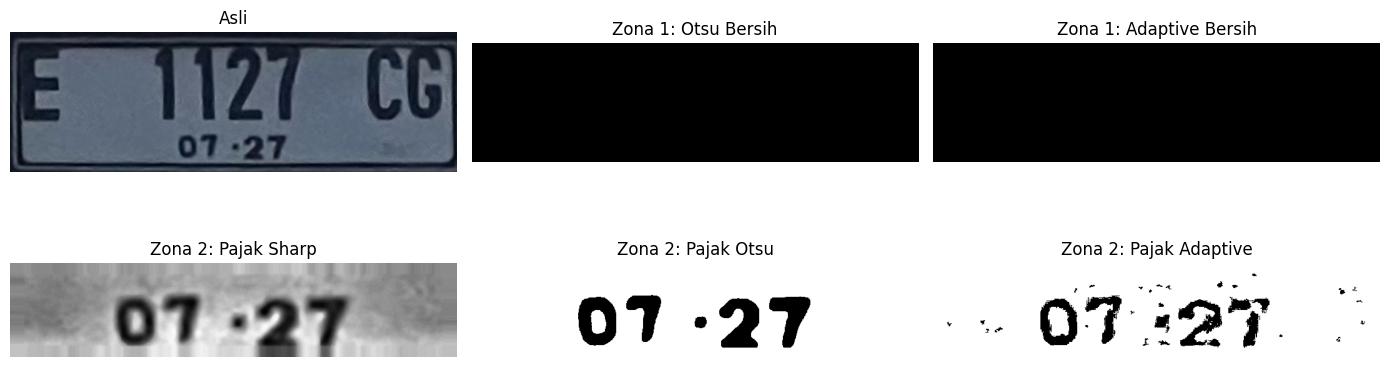

In [74]:
sample_path = os.path.join(dataset_root, "images/train/train004_2.jpg")
bgr = cv2.imread(sample_path)
gray, deskewed, smoothed, enhanced = preprocess_plate(bgr)
m_otsu, m_adap, m_sharp = process_main_plate_roi(enhanced)
t_otsu, t_adap, t_sharp = process_tax_roi(enhanced)

p_txt, p_conf, p_val = recognize_main_plate({"Otsu": m_otsu, "Adaptive": m_adap, "Sharp": m_sharp})
t_txt, t_conf, t_val = recognize_tax_date({"Sharp": t_sharp, "Otsu": t_otsu, "Adaptive": t_adap})

print(f"🚗 Plat Terbaca : {p_txt} (Conf: {p_conf} | Valid: {p_val}) | GT: {load_gt_from_txt(sample_path)}")
print(f"🗓️ Angka Pajak  : {t_txt} (Valid: {t_val})")

fig, axes = plt.subplots(2, 3, figsize=(14, 5))
axes[0, 0].imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)); axes[0, 0].set_title("Asli")
axes[0, 1].imshow(m_otsu, cmap="gray"); axes[0, 1].set_title("Zona 1: Otsu Bersih")
axes[0, 2].imshow(m_adap, cmap="gray"); axes[0, 2].set_title("Zona 1: Adaptive Bersih")
axes[1, 0].imshow(t_sharp, cmap="gray"); axes[1, 0].set_title("Zona 2: Pajak Sharp")
axes[1, 1].imshow(t_otsu, cmap="gray"); axes[1, 1].set_title("Zona 2: Pajak Otsu")
axes[1, 2].imshow(t_adap, cmap="gray"); axes[1, 2].set_title("Zona 2: Pajak Adaptive")
for ax in axes.flat: ax.axis("off")
plt.tight_layout(); plt.show()

🚗 Plat Terbaca : G 9058 EJ (Conf: 0.99 | Valid: True) | GT: G 9058 EJ
🗓️ Angka Pajak  : - (Valid: False)


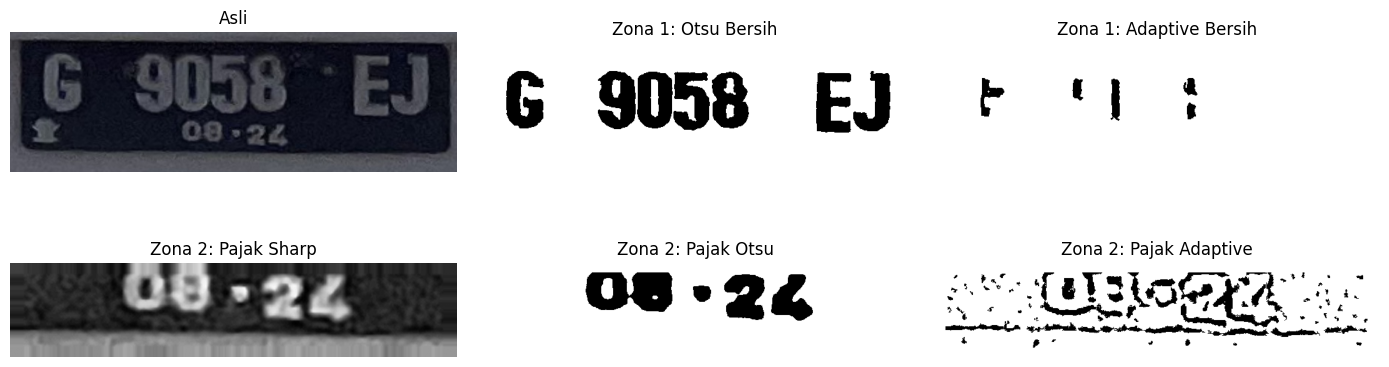

In [70]:
sample_path = os.path.join(dataset_root, "images/train/train001_1.jpg")
bgr = cv2.imread(sample_path)
gray, deskewed, smoothed, enhanced = preprocess_plate(bgr)
m_otsu, m_adap, m_sharp = process_main_plate_roi(enhanced)
t_otsu, t_adap, t_sharp = process_tax_roi(enhanced)

p_txt, p_conf, p_val = recognize_main_plate({"Otsu": m_otsu, "Adaptive": m_adap, "Sharp": m_sharp})
t_txt, t_conf, t_val = recognize_tax_date({"Sharp": t_sharp, "Otsu": t_otsu, "Adaptive": t_adap})

print(f"🚗 Plat Terbaca : {p_txt} (Conf: {p_conf} | Valid: {p_val}) | GT: {load_gt_from_txt(sample_path)}")
print(f"🗓️ Angka Pajak  : {t_txt} (Valid: {t_val})")

fig, axes = plt.subplots(2, 3, figsize=(14, 5))
axes[0, 0].imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)); axes[0, 0].set_title("Asli")
axes[0, 1].imshow(m_otsu, cmap="gray"); axes[0, 1].set_title("Zona 1: Otsu Bersih")
axes[0, 2].imshow(m_adap, cmap="gray"); axes[0, 2].set_title("Zona 1: Adaptive Bersih")
axes[1, 0].imshow(t_sharp, cmap="gray"); axes[1, 0].set_title("Zona 2: Pajak Sharp")
axes[1, 1].imshow(t_otsu, cmap="gray"); axes[1, 1].set_title("Zona 2: Pajak Otsu")
axes[1, 2].imshow(t_adap, cmap="gray"); axes[1, 2].set_title("Zona 2: Pajak Adaptive")
for ax in axes.flat: ax.axis("off")
plt.tight_layout(); plt.show()

🚗 Plat Terbaca : G 50 YGU (Conf: 0.46 | Valid: False) | GT: G 134 G
🗓️ Angka Pajak  : - (Valid: False)


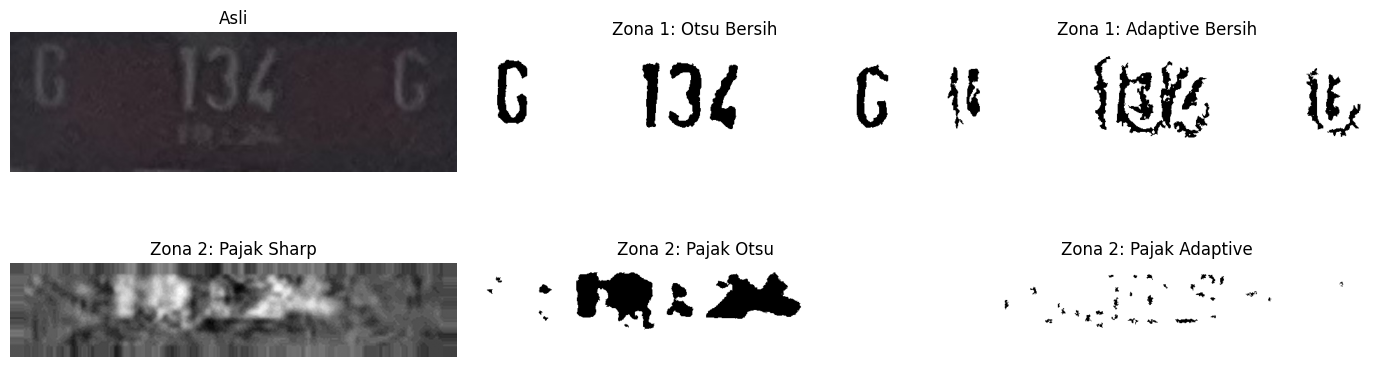

In [71]:
sample_path = os.path.join(dataset_root, "images/train/train002_2.jpg")
bgr = cv2.imread(sample_path)
gray, deskewed, smoothed, enhanced = preprocess_plate(bgr)
m_otsu, m_adap, m_sharp = process_main_plate_roi(enhanced)
t_otsu, t_adap, t_sharp = process_tax_roi(enhanced)

p_txt, p_conf, p_val = recognize_main_plate({"Otsu": m_otsu, "Adaptive": m_adap, "Sharp": m_sharp})
t_txt, t_conf, t_val = recognize_tax_date({"Sharp": t_sharp, "Otsu": t_otsu, "Adaptive": t_adap})

print(f"🚗 Plat Terbaca : {p_txt} (Conf: {p_conf} | Valid: {p_val}) | GT: {load_gt_from_txt(sample_path)}")
print(f"🗓️ Angka Pajak  : {t_txt} (Valid: {t_val})")

fig, axes = plt.subplots(2, 3, figsize=(14, 5))
axes[0, 0].imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)); axes[0, 0].set_title("Asli")
axes[0, 1].imshow(m_otsu, cmap="gray"); axes[0, 1].set_title("Zona 1: Otsu Bersih")
axes[0, 2].imshow(m_adap, cmap="gray"); axes[0, 2].set_title("Zona 1: Adaptive Bersih")
axes[1, 0].imshow(t_sharp, cmap="gray"); axes[1, 0].set_title("Zona 2: Pajak Sharp")
axes[1, 1].imshow(t_otsu, cmap="gray"); axes[1, 1].set_title("Zona 2: Pajak Otsu")
axes[1, 2].imshow(t_adap, cmap="gray"); axes[1, 2].set_title("Zona 2: Pajak Adaptive")
for ax in axes.flat: ax.axis("off")
plt.tight_layout(); plt.show()

🚗 Plat Terbaca : GI 1529 AAE (Conf: 0.09 | Valid: False) | GT: G 1529 AE
🗓️ Angka Pajak  : - (Valid: False)


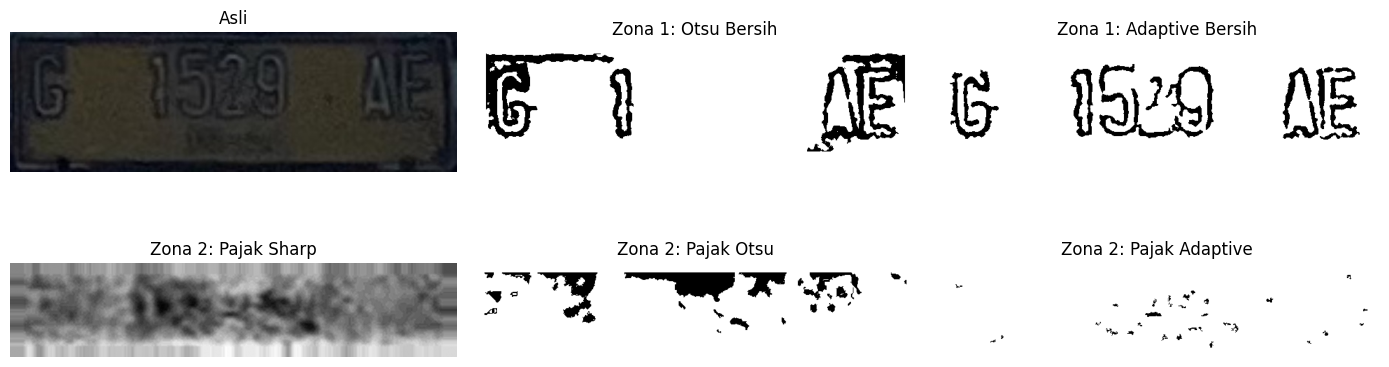

In [72]:
sample_path = os.path.join(dataset_root, "images/train/train005_2.jpg")
bgr = cv2.imread(sample_path)
gray, deskewed, smoothed, enhanced = preprocess_plate(bgr)
m_otsu, m_adap, m_sharp = process_main_plate_roi(enhanced)
t_otsu, t_adap, t_sharp = process_tax_roi(enhanced)

p_txt, p_conf, p_val = recognize_main_plate({"Otsu": m_otsu, "Adaptive": m_adap, "Sharp": m_sharp})
t_txt, t_conf, t_val = recognize_tax_date({"Sharp": t_sharp, "Otsu": t_otsu, "Adaptive": t_adap})

print(f"🚗 Plat Terbaca : {p_txt} (Conf: {p_conf} | Valid: {p_val}) | GT: {load_gt_from_txt(sample_path)}")
print(f"🗓️ Angka Pajak  : {t_txt} (Valid: {t_val})")

fig, axes = plt.subplots(2, 3, figsize=(14, 5))
axes[0, 0].imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)); axes[0, 0].set_title("Asli")
axes[0, 1].imshow(m_otsu, cmap="gray"); axes[0, 1].set_title("Zona 1: Otsu Bersih")
axes[0, 2].imshow(m_adap, cmap="gray"); axes[0, 2].set_title("Zona 1: Adaptive Bersih")
axes[1, 0].imshow(t_sharp, cmap="gray"); axes[1, 0].set_title("Zona 2: Pajak Sharp")
axes[1, 1].imshow(t_otsu, cmap="gray"); axes[1, 1].set_title("Zona 2: Pajak Otsu")
axes[1, 2].imshow(t_adap, cmap="gray"); axes[1, 2].set_title("Zona 2: Pajak Adaptive")
for ax in axes.flat: ax.axis("off")
plt.tight_layout(); plt.show()

🚗 Plat Terbaca : E 1275 SQ (Conf: 0.7 | Valid: True) | GT: E 1475 SD
🗓️ Angka Pajak  : 01-78 (Valid: True)


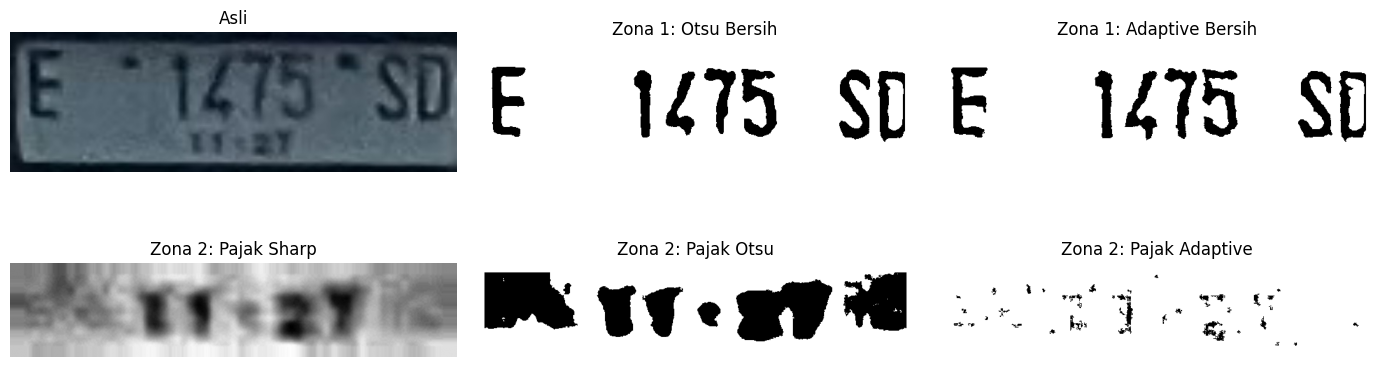

In [67]:
sample_path = os.path.join(dataset_root, "images/train/train008_2.jpg")
bgr = cv2.imread(sample_path)
gray, deskewed, smoothed, enhanced = preprocess_plate(bgr)
m_otsu, m_adap, m_sharp = process_main_plate_roi(enhanced)
t_otsu, t_adap, t_sharp = process_tax_roi(enhanced)

p_txt, p_conf, p_val = recognize_main_plate({"Otsu": m_otsu, "Adaptive": m_adap, "Sharp": m_sharp})
t_txt, t_conf, t_val = recognize_tax_date({"Sharp": t_sharp, "Otsu": t_otsu, "Adaptive": t_adap})

print(f"🚗 Plat Terbaca : {p_txt} (Conf: {p_conf} | Valid: {p_val}) | GT: {load_gt_from_txt(sample_path)}")
print(f"🗓️ Angka Pajak  : {t_txt} (Valid: {t_val})")

fig, axes = plt.subplots(2, 3, figsize=(14, 5))
axes[0, 0].imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)); axes[0, 0].set_title("Asli")
axes[0, 1].imshow(m_otsu, cmap="gray"); axes[0, 1].set_title("Zona 1: Otsu Bersih")
axes[0, 2].imshow(m_adap, cmap="gray"); axes[0, 2].set_title("Zona 1: Adaptive Bersih")
axes[1, 0].imshow(t_sharp, cmap="gray"); axes[1, 0].set_title("Zona 2: Pajak Sharp")
axes[1, 1].imshow(t_otsu, cmap="gray"); axes[1, 1].set_title("Zona 2: Pajak Otsu")
axes[1, 2].imshow(t_adap, cmap="gray"); axes[1, 2].set_title("Zona 2: Pajak Adaptive")
for ax in axes.flat: ax.axis("off")
plt.tight_layout(); plt.show()

[01/30] test001_1.jpg    | Pred: B 5140 BCD  | GT: B 9140 BCD  | Pajak: -      | Sharp:41.3  ❌
[02/30] test001_2.jpg    | ⚠️ TIDAK VALID (Buram, Sharp=9.4)
[03/30] test001_3.jpg    | ⚠️ TIDAK VALID (Buram, Sharp=39.0)
[04/30] test002_1.jpg    | ⚠️ TIDAK VALID (Buram, Sharp=9.4)
[05/30] test003_1.jpg    | Pred: B 2634 UZF  | GT: B 2634 UZF  | Pajak: 09-82  | Sharp:43.4  ✅
[06/30] test003_2.jpg    | Pred: B 1995 JVK  | GT: B 1995 JVK  | Pajak: 01-28  | Sharp:122.8 ✅
[07/30] test004_1.jpg    | ⚠️ TIDAK VALID (Buram, Sharp=3.1)
[08/30] test005_1.jpg    | ⚠️ TIDAK VALID (Buram, Sharp=3.8)
[09/30] test006_1.jpg    | ⚠️ TIDAK VALID (Buram, Sharp=5.6)
[10/30] test007_1.jpg    | ⚠️ TIDAK VALID (Buram, Sharp=21.7)
[11/30] test008_1.jpg    | Pred: DK 1157 AAB | GT: DK 1157 AAB | Pajak: 01-22  | Sharp:82.7  ✅
[12/30] test008_2.jpg    | ⚠️ TIDAK VALID (Buram, Sharp=13.1)
[13/30] test009_1.jpg    | ⚠️ TIDAK VALID (Buram, Sharp=18.1)
[14/30] test009_2.jpg    | Pred: I 649 GB    | GT: K 1649 GB   | Pa

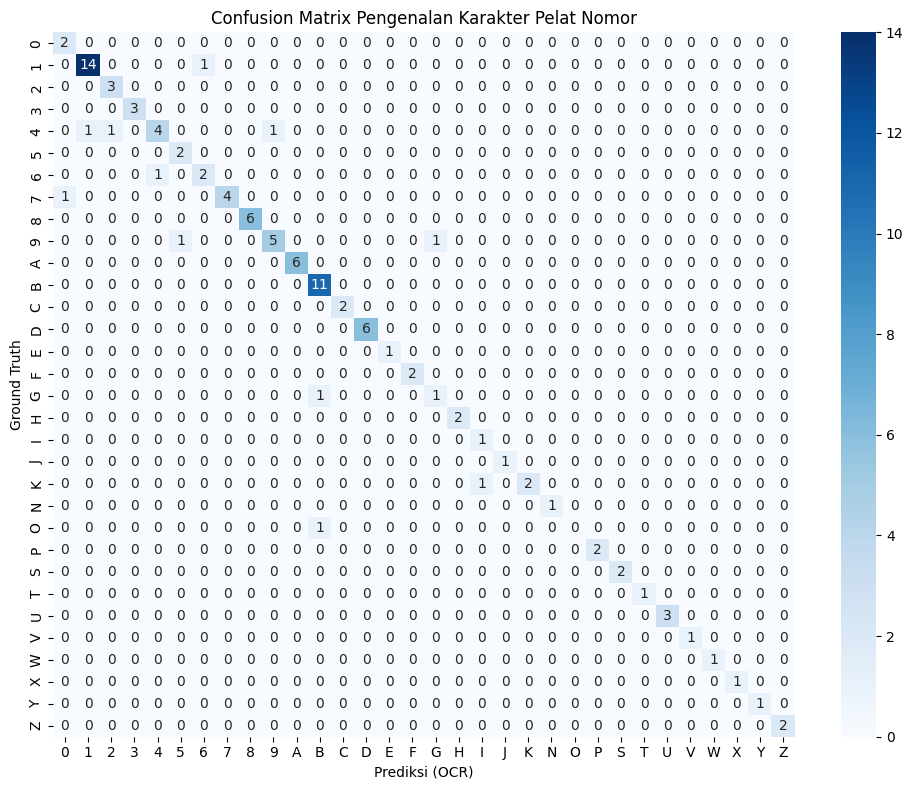

In [62]:
BLUR_THRESHOLD = 40.0
MAX_SAMPLES = 30  # Ubah ke None untuk semua gambar

test_imgs = sorted(glob.glob(f"{dataset_root}/images/test/*.jpg")) or sorted(glob.glob(f"{dataset_root}/images/train/*.jpg"))
eval_imgs = test_imgs[:MAX_SAMPLES] if MAX_SAMPLES else test_imgs

results_valid, skipped_blur = [], 0
y_true_chars, y_pred_chars = [], []

for idx, path in enumerate(eval_imgs, 1):
    bgr = cv2.imread(path)
    gray, _, _, enhanced = preprocess_plate(bgr)
    blurry, sharp_score = is_too_blurry(gray, BLUR_THRESHOLD)
    if blurry:
        skipped_blur += 1
        print(f"[{idx:02d}/{len(eval_imgs):02d}] {os.path.basename(path):<16} | ⚠️ TIDAK VALID (Buram, Sharp={sharp_score})")
        continue

    m_otsu, m_adap, m_sharp = process_main_plate_roi(enhanced)
    t_otsu, t_adap, t_sharp = process_tax_roi(enhanced)
    p_txt, p_conf, p_val = recognize_main_plate({"Otsu": m_otsu, "Adaptive": m_adap, "Sharp": m_sharp})
    t_txt, t_conf, t_val = recognize_tax_date({"Sharp": t_sharp, "Otsu": t_otsu, "Adaptive": t_adap})
    gt_txt = load_gt_from_txt(path)

    gt_c, pr_c = re.sub(r'[^A-Z0-9]', '', gt_txt), re.sub(r'[^A-Z0-9]', '', p_txt)
    sym = "✅" if gt_c == pr_c else "❌"
    print(f"[{idx:02d}/{len(eval_imgs):02d}] {os.path.basename(path):<16} | Pred: {p_txt:<11} | GT: {gt_txt:<11} | Pajak: {t_txt:<6} | Sharp:{sharp_score:<5} {sym}")

    results_valid.append({"bgr": bgr, "pred_plate": p_txt, "gt_plate": gt_txt, "pred_tax": t_txt, "tax_valid": t_val, "conf": p_conf})
    for k in range(max(len(gt_c), len(pr_c))):
        y_true_chars.append(gt_c[k] if k < len(gt_c) else "_")
        y_pred_chars.append(pr_c[k] if k < len(pr_c) else "_")

if results_valid:
    metrics = evaluate_ocr_metrics([r["pred_plate"] for r in results_valid], [r["gt_plate"] for r in results_valid])
    prec, rec, f1, _ = precision_recall_fscore_support(y_true_chars, y_pred_chars, average="weighted", zero_division=0)
    tax_rate = sum(1 for r in results_valid if r["tax_valid"]) / len(results_valid) * 100

    print("\n" + "="*62)
    print(f"📊 RINGKASAN METRIK (Valid: {len(results_valid)} | Buram/Dilewati: {skipped_blur})")
    print("="*62)
    print(f"1. Exact Match Accuracy   : {metrics['Exact Match Accuracy (%)']:.2f}%")
    print(f"2. Character Error (CER)  : {metrics['CER (%)']:.2f}%")
    print(f"3. Character Accuracy     : {metrics['Character Accuracy (%)']:.2f}%")
    print(f"4. Word Error Rate (WER)  : {metrics['WER (%)']:.2f}%")
    print(f"5. Character Precision    : {prec*100:.2f}%")
    print(f"6. Character Recall       : {rec*100:.2f}%")
    print(f"7. Character F1-Score     : {f1*100:.2f}%")
    print(f"8. Pajak Valid Terbaca    : {tax_rate:.2f}% (Opsional)")
    print("="*62)

    labels_unique = sorted(list(set(y_true_chars + y_pred_chars) - {"_"}))
    cm = confusion_matrix(y_true_chars, y_pred_chars, labels=labels_unique)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels_unique, yticklabels=labels_unique)
    plt.title("Confusion Matrix Pengenalan Karakter Pelat Nomor")
    plt.xlabel("Prediksi (OCR)"); plt.ylabel("Ground Truth")
    plt.tight_layout(); plt.show()